## 2. A1-selected settings

No hyperparameter search is repeated in A2. All variants inherit the architecture/training choices selected in A1 so that the ablations change only the component being tested.

## 1. Environment and project setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader

ROOT = Path.cwd()
SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from config import Config
from data import make_dataset
from model import PriceModel

DATA_PATH = ROOT / "hdb_price_prediction.csv"
OUTPUT_DIR = ROOT / "outputs" / "A2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Data exists:", DATA_PATH.exists())
print("PyTorch version:", torch.__version__)

Project root: d:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main
Data exists: True
PyTorch version: 2.13.0+cpu


### Environment verification

Part A1 and Part A2 are intended to run from the same project root and the same project `.venv`.  
The cell below records the exact Python executable and package versions used at runtime. When preparing the final ZIP/README, run both notebooks with the same VS Code kernel and confirm that these values match.

In [ ]:
from importlib.metadata import version as package_version

python_executable = Path(sys.executable).resolve()
project_venv = (ROOT / ".venv").resolve()

print("Python executable:", python_executable)
print("Python version:", sys.version.split()[0])
print("Project .venv:", project_venv)
print("Using project .venv:", str(project_venv).lower() in str(python_executable).lower())

for package in ["torch", "ray", "pandas", "numpy", "matplotlib"]:
    try:
        print(f"{package}: {package_version(package)}")
    except Exception:
        print(f"{package}: not installed")

## 2. A1-selected settings

In [2]:
# Selected in Part A1
HIDDEN_WIDTH = 256
EMBEDDING_DIM = 2
NUM_EPOCHS = 10

# Five distinct seeds used for the baseline and both ablations
SEEDS = [42, 43, 44, 45, 46]

base_config = Config()

print("Hidden width:", HIDDEN_WIDTH)
print("Shared embedding dimension:", EMBEDDING_DIM)
print("Number of epochs:", NUM_EPOCHS)
print("Learning rate:", base_config.learning_rate)
print("Batch size:", base_config.batch_size)
print("Seeds:", SEEDS)

Hidden width: 256
Shared embedding dimension: 2
Number of epochs: 10
Learning rate: 0.01
Batch size: 512
Seeds: [42, 43, 44, 45, 46]


## 3. Prepare combined train + validation data

For A2, all models are trained on **2017–2021**. The categorical encoders, continuous-feature mean/standard deviation, and target mean/standard deviation are therefore fit on the same combined training data. The 2022 test set is transformed using these quantities and does not contribute to them.

This preprocessing logic is intentionally the same as the final-retraining stage in Part A1.

In [3]:
def prepare_combined_data(csv_path, config):
    df = pd.read_csv(csv_path)
    rows = df.to_dict(orient="records")

    combined_rows = [
        row for row in rows
        if int(row["year"]) in config.train_years
        or int(row["year"]) == config.validation_year
    ]

    test_rows = [
        row for row in rows
        if int(row["year"]) == config.test_year
    ]

    # Fit categorical encoders on combined 2017–2021 data.
    # ID 0 remains reserved for categories unseen in the combined training data.
    category_maps = {}
    for name in config.categorical_features:
        values = sorted({row[name] for row in combined_rows})
        category_maps[name] = {value: index + 1 for index, value in enumerate(values)}

    # Fit continuous-feature scaling on combined 2017–2021 data.
    combined_continuous = torch.tensor(
        [
            [float(row[name]) for name in config.continuous_features]
            for row in combined_rows
        ],
        dtype=torch.float32
    )

    means = combined_continuous.mean(dim=0)
    stds = combined_continuous.std(dim=0).clamp_min(1e-8)

    # Fit target scaling on combined 2017–2021 data.
    combined_target = torch.tensor(
        [float(row["resale_price"]) for row in combined_rows],
        dtype=torch.float32
    )

    target_mean = combined_target.mean().item()
    target_std = combined_target.std(correction=0).clamp_min(1e-8).item()

    return {
        "combined": make_dataset(combined_rows, category_maps, means, stds, config),
        "test": make_dataset(test_rows, category_maps, means, stds, config),
        "cardinalities": [
            len(category_maps[name]) + 1
            for name in config.categorical_features
        ],
        "continuous_mean": means,
        "continuous_std": stds,
        "target_mean": target_mean,
        "target_std": target_std
    }

In [4]:
check_config = Config(
    seed=SEEDS[0],
    hidden_width=HIDDEN_WIDTH,
    embedding_dims=(EMBEDDING_DIM,) * 4
)

check_data = prepare_combined_data(DATA_PATH, check_config)

print("Combined training rows:", len(check_data["combined"]))
print("Test rows:", len(check_data["test"]))
print("Embedding cardinalities:", check_data["cardinalities"])
print("Target mean:", f'{check_data["target_mean"]:,.2f}')
print("Target std:", f'{check_data["target_std"]:,.2f}')

Combined training rows: 116427
Test rows: 26702
Embedding cardinalities: [13, 27, 44, 18]
Target mean: 459,696.81
Target std: 159,183.88


## 4. Model variants

### 4.1 Ablation (a): continuous features only

All four categorical inputs and embedding tables are removed. The model therefore receives only the six continuous features. The hidden width remains 256, so the first linear layer becomes **6 → 256**.

In [5]:
class ContinuousOnlyModel(nn.Module):
    def __init__(self, target_mean, target_std, hidden_width):
        super().__init__()

        self.mlp = nn.Sequential(
            nn.Linear(6, hidden_width),
            nn.LayerNorm(hidden_width),
            nn.ReLU(),
            nn.Linear(hidden_width, 1)
        )

        self.target_mean = target_mean
        self.target_std = target_std

    def forward(self, continuous):
        return self.mlp(continuous).squeeze(1)

    def predict_price(self, continuous):
        return self(continuous) * self.target_std + self.target_mean

### 4.2 Ablation (b): Sigmoid instead of ReLU

The categorical embeddings and all six continuous inputs are retained. The only architectural change from the A1 baseline is **ReLU → Sigmoid**.

In [6]:
class SigmoidPriceModel(nn.Module):
    def __init__(self, cardinalities, target_mean, target_std, config):
        super().__init__()

        self.embeddings = nn.ModuleList(
            nn.Embedding(cardinality, width)
            for cardinality, width in zip(cardinalities, config.embedding_dims)
        )

        input_width = sum(config.embedding_dims) + len(config.continuous_features)

        self.mlp = nn.Sequential(
            nn.Linear(input_width, config.hidden_width),
            nn.LayerNorm(config.hidden_width),
            nn.Sigmoid(),
            nn.Linear(config.hidden_width, 1)
        )

        self.target_mean = target_mean
        self.target_std = target_std

    def forward(self, categorical, continuous):
        embedded = [
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ]
        features = torch.cat(embedded + [continuous], dim=1)
        return self.mlp(features).squeeze(1)

    def predict_price(self, categorical, continuous):
        return self(categorical, continuous) * self.target_std + self.target_mean

## 5. Evaluation and training functions

Every run uses exactly the **10 epochs selected in A1**. There is no new early-stopping or model-selection step in A2. Test RMSE and $R^2$ are computed once after each trained model has completed its 10 epochs.

Training RMSE is retained at every epoch to compare optimisation behaviour without repeatedly using the test set during training.

In [7]:
@torch.no_grad()
def evaluate_variant(model, dataset, batch_size, variant):
    model.eval()
    predictions = []
    targets = []

    for categorical, continuous, target in DataLoader(dataset, batch_size=batch_size):
        if variant == "no_embeddings":
            prediction = model.predict_price(continuous)
        else:
            prediction = model.predict_price(categorical, continuous)

        predictions.append(prediction)
        targets.append(target)

    predictions = torch.cat(predictions)
    targets = torch.cat(targets)

    rmse = (predictions - targets).square().mean().sqrt().item()

    ss_res = (targets - predictions).square().sum()
    ss_tot = (targets - targets.mean()).square().sum()
    r2 = (1 - ss_res / ss_tot).item()

    return rmse, r2

In [8]:
def train_variant(variant, seed, verbose=False):
    config = Config(
        seed=seed,
        hidden_width=HIDDEN_WIDTH,
        embedding_dims=(EMBEDDING_DIM,) * 4
    )

    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

    data = prepare_combined_data(DATA_PATH, config)
    combined_data = data["combined"]

    if variant == "baseline":
        model = PriceModel(
            data["cardinalities"],
            data["target_mean"],
            data["target_std"],
            config
        )

    elif variant == "no_embeddings":
        model = ContinuousOnlyModel(
            target_mean=data["target_mean"],
            target_std=data["target_std"],
            hidden_width=HIDDEN_WIDTH
        )

    elif variant == "sigmoid":
        model = SigmoidPriceModel(
            data["cardinalities"],
            data["target_mean"],
            data["target_std"],
            config
        )

    else:
        raise ValueError(f"Unknown variant: {variant}")

    train_loader = DataLoader(
        combined_data,
        batch_size=config.batch_size,
        shuffle=True
    )

    loss_function = nn.MSELoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=config.learning_rate)

    train_rmse_history = []

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        squared_error = 0.0
        row_count = 0

        for categorical, continuous, target in train_loader:
            optimiser.zero_grad()

            if variant == "no_embeddings":
                standard_prediction = model(continuous)
            else:
                standard_prediction = model(categorical, continuous)

            standard_target = (target - model.target_mean) / model.target_std

            loss = loss_function(standard_prediction, standard_target)
            loss.backward()
            optimiser.step()

            prediction = (
                standard_prediction.detach()
                * model.target_std
                + model.target_mean
            )

            squared_error += (prediction - target).square().sum().item()
            row_count += len(target)

        train_rmse = (squared_error / row_count) ** 0.5
        train_rmse_history.append(train_rmse)

        if verbose:
            print(
                f"{variant:14s} | seed {seed:2d} | epoch {epoch:02d} | "
                f"train RMSE {train_rmse:,.2f}"
            )

    # Test set is evaluated once after training.
    test_rmse, test_r2 = evaluate_variant(
        model,
        data["test"],
        config.batch_size,
        variant
    )

    return {
        "variant": variant,
        "seed": seed,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "train_rmse_history": train_rmse_history
    }

## 6. Run the 15 experiments

The same five seeds are used for the baseline and both ablations, giving **3 variants × 5 seeds = 15 runs**. Using matched seeds also permits paired seed-wise comparisons.

In [9]:
VARIANTS = ["baseline", "no_embeddings", "sigmoid"]

MODEL_LABELS = {
    "baseline": "Baseline (ReLU + embeddings)",
    "no_embeddings": "No embeddings",
    "sigmoid": "Sigmoid"
}

results = []
training_histories = {}

for variant in VARIANTS:
    print(f"\nRunning {MODEL_LABELS[variant]}")

    for seed in SEEDS:
        result = train_variant(variant, seed, verbose=False)

        training_histories[(variant, seed)] = result["train_rmse_history"]

        results.append({
            "variant": variant,
            "seed": seed,
            "test_rmse": result["test_rmse"],
            "test_r2": result["test_r2"]
        })

        print(
            f"seed {seed} | "
            f"test RMSE {result['test_rmse']:,.2f} | "
            f"test R² {result['test_r2']:.4f}"
        )

results_df = pd.DataFrame(results)
results_df


Running Baseline (ReLU + embeddings)
seed 42 | test RMSE 103,070.77 | test R² 0.6335
seed 43 | test RMSE 98,039.13 | test R² 0.6684
seed 44 | test RMSE 111,031.43 | test R² 0.5747
seed 45 | test RMSE 95,936.17 | test R² 0.6825
seed 46 | test RMSE 97,047.53 | test R² 0.6751

Running No embeddings
seed 42 | test RMSE 107,243.85 | test R² 0.6032
seed 43 | test RMSE 112,072.80 | test R² 0.5667
seed 44 | test RMSE 105,421.41 | test R² 0.6166
seed 45 | test RMSE 109,293.17 | test R² 0.5879
seed 46 | test RMSE 114,678.37 | test R² 0.5463

Running Sigmoid
seed 42 | test RMSE 104,612.98 | test R² 0.6225
seed 43 | test RMSE 79,344.31 | test R² 0.7828
seed 44 | test RMSE 102,777.16 | test R² 0.6356
seed 45 | test RMSE 90,514.26 | test R² 0.7174
seed 46 | test RMSE 105,619.54 | test R² 0.6152


,variant,seed,test_rmse,test_r2
0,baseline,42,103070.765625,0.633526
1,baseline,43,98039.132812,0.668433
2,baseline,44,111031.429688,0.574730
3,baseline,45,95936.171875,0.682505
4,baseline,46,97047.531250,0.675106
5,no_embeddings,42,107243.851562,0.603250
6,no_embeddings,43,112072.804688,0.566716
7,no_embeddings,44,105421.414062,0.616619
8,no_embeddings,45,109293.171875,0.587942
9,no_embeddings,46,114678.367188,0.546335


## 7. Mean and sample standard deviation across five seeds

The assignment requires the mean and standard deviation of test RMSE and $R^2$. The reported SD below is the **sample standard deviation** (`ddof=1`) across the five seeds.

In [10]:
summary_df = (
    results_df
    .groupby("variant", sort=False)
    .agg(
        test_rmse_mean=("test_rmse", "mean"),
        test_rmse_sd=("test_rmse", "std"),
        test_r2_mean=("test_r2", "mean"),
        test_r2_sd=("test_r2", "std")
    )
    .reset_index()
)

summary_df["model"] = summary_df["variant"].map(MODEL_LABELS)

baseline_rmse = summary_df.loc[
    summary_df["variant"] == "baseline", "test_rmse_mean"
].iloc[0]

baseline_r2 = summary_df.loc[
    summary_df["variant"] == "baseline", "test_r2_mean"
].iloc[0]

summary_df["delta_rmse_vs_baseline"] = summary_df["test_rmse_mean"] - baseline_rmse
summary_df["delta_r2_vs_baseline"] = summary_df["test_r2_mean"] - baseline_r2

summary_df = summary_df[
    [
        "variant",
        "model",
        "test_rmse_mean",
        "test_rmse_sd",
        "test_r2_mean",
        "test_r2_sd",
        "delta_rmse_vs_baseline",
        "delta_r2_vs_baseline"
    ]
]

summary_df

,variant,model,test_rmse_mean,test_rmse_sd,test_r2_mean,test_r2_sd,delta_rmse_vs_baseline,delta_r2_vs_baseline
0,baseline,Baseline (ReLU + embeddings),101025.006250,6223.857813,0.646860,0.044481,0.000000,0.000000
1,no_embeddings,No embeddings,109741.921875,3705.065000,0.584172,0.028140,8716.915625,-0.062688
2,sigmoid,Sigmoid,96573.651563,11385.395220,0.674694,0.072992,-4451.354688,0.027834


In [11]:
report_table = summary_df[["model"]].copy()

report_table["Test RMSE (mean ± SD)"] = summary_df.apply(
    lambda row: f'{row["test_rmse_mean"]:,.0f} ± {row["test_rmse_sd"]:,.0f}',
    axis=1
)

report_table["Test R² (mean ± SD)"] = summary_df.apply(
    lambda row: f'{row["test_r2_mean"]:.4f} ± {row["test_r2_sd"]:.4f}',
    axis=1
)

report_table["ΔRMSE vs baseline"] = summary_df["delta_rmse_vs_baseline"].map(
    lambda value: f"{value:+,.0f}"
)

report_table["ΔR² vs baseline"] = summary_df["delta_r2_vs_baseline"].map(
    lambda value: f"{value:+.4f}"
)

report_table

,model,Test RMSE (mean ± SD),Test R² (mean ± SD),ΔRMSE vs baseline,ΔR² vs baseline
0,Baseline (ReLU + embeddings),"101,025 ± 6,224",0.6469 ± 0.0445,+0,+0.0000
1,No embeddings,"109,742 ± 3,705",0.5842 ± 0.0281,"+8,717",-0.0627
2,Sigmoid,"96,574 ± 11,385",0.6747 ± 0.0730,"-4,451",+0.0278


## 8. Paired seed-wise differences

Because all variants use the same five seeds, paired differences provide an additional diagnostic:
- positive $\Delta$RMSE means the ablation is worse than the baseline;
- negative $\Delta R^2$ means the ablation is worse than the baseline.

These paired summaries complement, rather than replace, the required mean ± SD results.

In [12]:
baseline_seed = (
    results_df[results_df["variant"] == "baseline"]
    [["seed", "test_rmse", "test_r2"]]
    .rename(columns={
        "test_rmse": "baseline_rmse",
        "test_r2": "baseline_r2"
    })
)

paired_rows = []

for variant in ["no_embeddings", "sigmoid"]:
    ablation_seed = (
        results_df[results_df["variant"] == variant]
        [["seed", "test_rmse", "test_r2"]]
        .rename(columns={
            "test_rmse": "ablation_rmse",
            "test_r2": "ablation_r2"
        })
    )

    paired = baseline_seed.merge(ablation_seed, on="seed")
    paired["variant"] = variant
    paired["delta_rmse"] = paired["ablation_rmse"] - paired["baseline_rmse"]
    paired["delta_r2"] = paired["ablation_r2"] - paired["baseline_r2"]

    paired_rows.append(paired)

paired_df = pd.concat(paired_rows, ignore_index=True)

paired_summary_df = (
    paired_df
    .groupby("variant", sort=False)
    .agg(
        mean_delta_rmse=("delta_rmse", "mean"),
        sd_delta_rmse=("delta_rmse", "std"),
        mean_delta_r2=("delta_r2", "mean"),
        sd_delta_r2=("delta_r2", "std")
    )
    .reset_index()
)

paired_df

,seed,baseline_rmse,baseline_r2,ablation_rmse,ablation_r2,variant,delta_rmse,delta_r2
0,42,103070.765625,0.633526,107243.851562,0.603250,no_embeddings,4173.085938,-0.030276
1,43,98039.132812,0.668433,112072.804688,0.566716,no_embeddings,14033.671875,-0.101717
2,44,111031.429688,0.574730,105421.414062,0.616619,no_embeddings,-5610.015625,0.041889
3,45,95936.171875,0.682505,109293.171875,0.587942,no_embeddings,13357.000000,-0.094563
4,46,97047.531250,0.675106,114678.367188,0.546335,no_embeddings,17630.835938,-0.128772
5,42,103070.765625,0.633526,104612.984375,0.622477,sigmoid,1542.218750,-0.011049
6,43,98039.132812,0.668433,79344.312500,0.782828,sigmoid,-18694.820312,0.114395
7,44,111031.429688,0.574730,102777.164062,0.635610,sigmoid,-8254.265625,0.060880
8,45,95936.171875,0.682505,90514.257812,0.717378,sigmoid,-5421.914062,0.034873
9,46,97047.531250,0.675106,105619.539062,0.615177,sigmoid,8572.007812,-0.059929


In [13]:
paired_summary_df

,variant,mean_delta_rmse,sd_delta_rmse,mean_delta_r2,sd_delta_r2
0,no_embeddings,8716.915625,9422.892372,-0.062688,0.068726
1,sigmoid,-4451.354688,10293.339150,0.027834,0.066799


## 9. Test RMSE across five seeds

Each small point is one seed. The diamond shows the five-seed mean and the error bar shows **±1 sample SD**.

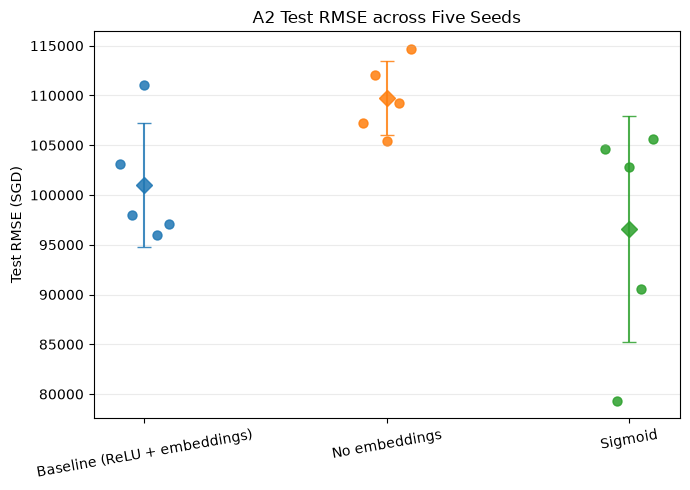

In [14]:
x_positions = np.arange(len(VARIANTS))
jitter = np.linspace(-0.10, 0.10, len(SEEDS))

plt.figure(figsize=(7, 5))

for x, variant in zip(x_positions, VARIANTS):
    values = (
        results_df[results_df["variant"] == variant]
        .sort_values("seed")["test_rmse"]
        .to_numpy()
    )

    scatter = plt.scatter(
        x + jitter,
        values,
        s=42,
        alpha=0.85,
        label=MODEL_LABELS[variant]
    )

    mean_value = values.mean()
    sd_value = values.std(ddof=1)

    plt.errorbar(
        x,
        mean_value,
        yerr=sd_value,
        fmt="D",
        markersize=8,
        capsize=5,
        linewidth=1.5,
        color=scatter.get_facecolor()[0]
    )

plt.xticks(x_positions, [MODEL_LABELS[v] for v in VARIANTS], rotation=10)
plt.ylabel("Test RMSE (SGD)")
plt.title("A2 Test RMSE across Five Seeds")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "A2_test_rmse_by_seed.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Test $R^2$ across five seeds

Each small point is one seed. The diamond shows the five-seed mean and the error bar shows **±1 sample SD**.

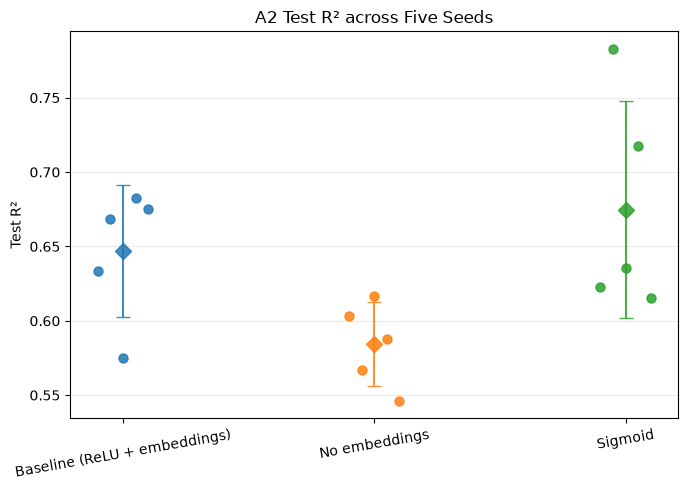

In [15]:
plt.figure(figsize=(7, 5))

for x, variant in zip(x_positions, VARIANTS):
    values = (
        results_df[results_df["variant"] == variant]
        .sort_values("seed")["test_r2"]
        .to_numpy()
    )

    scatter = plt.scatter(
        x + jitter,
        values,
        s=42,
        alpha=0.85,
        label=MODEL_LABELS[variant]
    )

    mean_value = values.mean()
    sd_value = values.std(ddof=1)

    plt.errorbar(
        x,
        mean_value,
        yerr=sd_value,
        fmt="D",
        markersize=8,
        capsize=5,
        linewidth=1.5,
        color=scatter.get_facecolor()[0]
    )

plt.xticks(x_positions, [MODEL_LABELS[v] for v in VARIANTS], rotation=10)
plt.ylabel("Test R²")
plt.title("A2 Test R² across Five Seeds")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "A2_test_r2_by_seed.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Training RMSE across five seeds

For each variant, the line is the mean training RMSE at each epoch and the shaded band is **±1 sample SD** across the five seeds. This plot helps distinguish optimisation/fit effects from test-set variability.

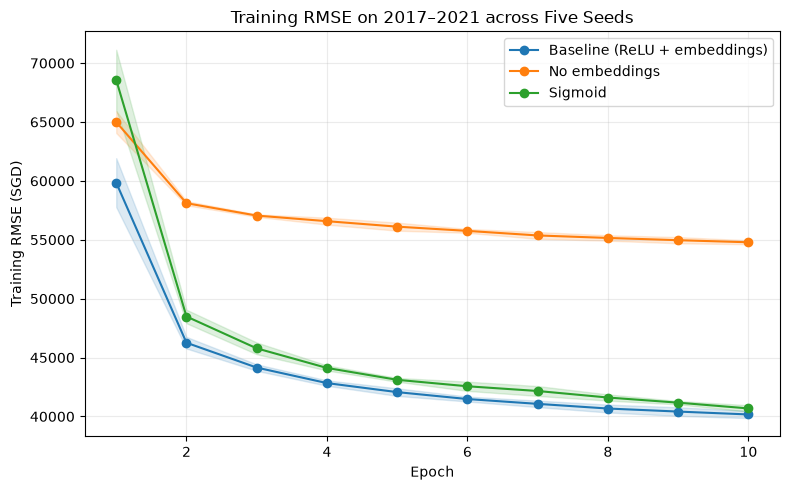

In [16]:
epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))

for variant in VARIANTS:
    history_matrix = np.array([
        training_histories[(variant, seed)]
        for seed in SEEDS
    ])

    mean_history = history_matrix.mean(axis=0)
    sd_history = history_matrix.std(axis=0, ddof=1)

    line, = plt.plot(
        epochs,
        mean_history,
        marker="o",
        label=MODEL_LABELS[variant]
    )

    plt.fill_between(
        epochs,
        mean_history - sd_history,
        mean_history + sd_history,
        alpha=0.15,
        color=line.get_color()
    )

plt.xlabel("Epoch")
plt.ylabel("Training RMSE (SGD)")
plt.title("Training RMSE on 2017–2021 across Five Seeds")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "A2_training_rmse_mean_sd.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Save experiment outputs

In [17]:
history_rows = []

for (variant, seed), history in training_histories.items():
    for epoch, train_rmse in enumerate(history, start=1):
        history_rows.append({
            "variant": variant,
            "seed": seed,
            "epoch": epoch,
            "train_rmse": train_rmse
        })

training_history_df = pd.DataFrame(history_rows)

results_df.to_csv(OUTPUT_DIR / "A2_seed_level_results.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "A2_summary_mean_sd.csv", index=False)
paired_df.to_csv(OUTPUT_DIR / "A2_paired_seed_differences.csv", index=False)
paired_summary_df.to_csv(OUTPUT_DIR / "A2_paired_difference_summary.csv", index=False)
training_history_df.to_csv(OUTPUT_DIR / "A2_training_rmse_history.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR)

Saved outputs to: d:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main\outputs\A2


## 13. A2 results and interpretation

### Ablation (a): removing categorical embeddings

The baseline achieved **SGD 101,025 ± 6,224** test RMSE and **$R^2 = 0.6469 ± 0.0445$**. Removing the four categorical embedding inputs increased mean test RMSE to **SGD 109,742 ± 3,705** and reduced mean $R^2$ to **0.5842 ± 0.0281**.

Relative to the baseline, this is:
- **+SGD 8,717 RMSE** (about **8.6% worse**);
- **−0.0627 $R^2$**.

The no-embedding model is worse than the matched baseline in **4 of 5 seeds**; seed 44 is the exception. Its training-RMSE curve also remains substantially above the baseline throughout training. Together, these results indicate that the categorical inputs provide useful predictive information beyond the six continuous features.

This ablation removes both the **categorical information** and the **embedding tables**, so the experiment should not be interpreted as isolating the embedding mechanism alone.

### Ablation (b): Sigmoid instead of ReLU

Replacing ReLU with Sigmoid produced a mean test RMSE of **SGD 96,574 ± 11,385** and mean **$R^2 = 0.6747 ± 0.0730$**. On average this is:
- **−SGD 4,451 RMSE** (about **4.4% better**);
- **+0.0278 $R^2$**.

However, the Sigmoid model is much more variable across seeds: its RMSE SD is **SGD 11,385**, compared with **SGD 6,224** for the baseline. It improves RMSE in **3 of 5 matched seeds** and worsens it in 2. Its training RMSE is slightly higher than the ReLU baseline for most of training, so the better mean test result is not explained by achieving a lower training error.

Therefore the evidence does **not** support the claim that replacing ReLU with Sigmoid consistently improves the model. A more cautious conclusion is that Sigmoid produced better average test performance in these five runs but with substantially lower stability. LayerNorm before the activation may also reduce the severe saturation behaviour often associated with Sigmoid in deeper, unnormalised networks.

### Overall conclusion

The strongest A2 finding is the importance of the categorical inputs: removing them clearly worsens both training fit and average test performance. The activation-function comparison is less decisive because the Sigmoid variant has better mean metrics but noticeably larger seed-to-seed variation. With only five seeds, the results should be interpreted as evidence about these runs rather than a general proof that one activation is universally superior.